# From the Mutual Fund Theorem to the Security Market Line
### Does the theory survive real data?

**FE 5108 Portfolio Theory and Investments, Group project**

*Risk Management Institute, National University of Singapore*

---

This notebook is the report and the evidence together. Every table and figure is
generated from the committed data under `data/`.

**Contents**

1. [Executive summary](#1-executive-summary)
2. [Data and methodology](#2-data-and-methodology)
3. [Stage 1: portfolio choice and estimation error](#3-stage-1-portfolio-choice-and-estimation-error)
4. [Stage 2: the CAPM and the empirical SML](#4-stage-2-the-capm-and-the-empirical-sml)
5. [Stage 3: factors](#5-stage-3-factors)
6. [Robustness: the market proxy](#6-robustness-the-market-proxy)
7. [Stage 4: the memo to the investment committee](#7-stage-4-the-memo-to-the-investment-committee)
8. [Out-of-sample validation](#8-out-of-sample-validation)


## 1. Executive summary

We estimate mean variance portfolios and test the CAPM on 30 US securities over
119 months, then repeat on 29 Singapore names. The theory organises risk well. It
does not build a portfolio well.

**Portfolio choice (Stage 1).** The tangency portfolio fails first. In the US it
shorts one stock by 280% and its weights correlate at only 0.35 across the two
halves of the sample; Singapore is worse, at -0.10. A no-short constraint and
shrinkage cut the largest US position from 280% to 11% and gross leverage from
16x to 1.3x, and out of sample the shrunk long-only version earns a Sharpe of 0.95
against 0.69 for the raw solution.

**The CAPM (Stage 2).** The security market line also misses: the US slope is
0.016 against a theoretical 0.019 and the fitted intercept is 0.000, while
Singapore's slope is 0.018 against 0.014 and its intercept is a negative -0.006.
The alphas are kinder. The US joint test cannot reject zero (GRS p = 0.47), with
2 of 30 assets past |t| > 2, about the count expected by chance; Singapore is
marginal (p = 0.09) with 6 of 29 significant.

**Factors (Stage 3).** Adding size and momentum changes little in the US, where
nothing was badly wrong to begin with: mean |alpha| stays at 0.40% a month and no
joint test rejects. In Singapore the self-built size and momentum spreads absorb
the *level* of the Stage-2 anomaly - mean |alpha| falls from 0.88% to 0.64% a
month, five of the eight CAPM alphas lose significance, and the worst (Y92) falls
from +4.3% to +0.5% a month. The joint rejection tightens as the factors shrink
the residual covariance faster than the alphas (GRS p 0.02 to 0.006), so a smaller
per-asset alpha and a stronger joint test coexist. Factors explain the size of the
anomaly, not all of it.

**Judgment (Stage 4).** The verdict moves with the market proxy, which lifts the
US GRS p from 0.47 to 0.19 and shifts the average beta by 0.17 on the same assets
- a reminder that a CAPM test is a joint test of the model and the proxy. We would
hold the value-weighted index, or a shrunk long-only tilt, not the raw tangency
portfolio.


## 2. Data and methodology

We use 30 US securities (21 large capitalisation companies, 9 sector ETFs) over
119 months, October 2016 to August 2026, and repeat the CAPM on 29 Singapore
listings. Returns are month end Yahoo prices adjusted for splits and dividends.
Tickers below 90 clean observations are dropped, and a month is kept only when
every asset has a price, so the panel is balanced and the covariance matrix is
invertible.

The US risk free rate is the Fama and French one month Treasury bill. Singapore
uses the MAS compounded SORA index, converted to monthly as the ratio of
consecutive month end levels. The market proxy defaults to a value weighted
composite of the same universe, replaced in Section 6 by the Fama and French
factor. For Stage 3 we use Ken French's market factor as the US benchmark and
build size and momentum long-short spreads from the same universe for both
markets.

Every return is a total return in the asset's **local currency**: the US series
is in USD and the Singapore series in SGD, and we do not convert to a common
currency. The two markets are therefore compared on their own terms; an SGD
investor holding the US names would also bear the USD/SGD move, which is outside
this analysis.

Three limitations matter. First, **survivorship bias**: both universes use
today's members carried back to 2016, so failed or delisted firms are missing.
This biases average returns and alphas **upward** - the Stage 1 means, the Stage 2
and 3 alpha estimates and the fitted SML all look better than a live investor's
experience - and it understates the tail the optimiser would have faced. Second,
delistings are absent rather than modelled, so no return is truncated at a
bankruptcy. Third, early Yahoo share counts are incomplete for a few names, so a
handful of market caps in the point-in-time value weights are approximations.


**Exhibit 1. The sample.** What the two universes cover.

**Takeaway.** Both panels are balanced, ten-year monthly samples - 119 months
from October 2016 to August 2026, 30 US names (21 mega-caps plus 9 sector ETFs)
and 29 Singapore listings. Because every surviving asset has a price in every
month, the covariance matrix is invertible and every cross-sectional regression
runs on a common window, so no test is quietly computed on a different sample
from its neighbour.


In [1]:
import base64
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display

from goldman import viz
from goldman.analysis import run_capm_analysis, run_portfolio_analysis
from goldman.config import ensure_outputs_dir, get_universe
from goldman.data import load_ff3, load_returns, load_value_weights, risk_free_series

# Figure display config: show every exhibit centred at a fixed pixel width.
# JupyterLab and VS Code both ignore the width metadata IPython attaches to
# image/png output, so render an HTML <img> with an explicit width instead.
FIGURE_WIDTH = 700


def Image(filename=None, *, width=FIGURE_WIDTH, alt="", **kwargs):
    """Render a PNG as a centred HTML image of a fixed pixel width."""
    encoded = base64.b64encode(Path(filename).read_bytes()).decode("ascii")
    return HTML(
        f'<div style="text-align:center">'
        f'<img src="data:image/png;base64,{encoded}" width="{width}" alt="{alt}">'
        f"</div>"
    )

# The Fama and French market factor is published with a one month lag, so the
# Roll check in section 6 estimates on the sample the two proxies share.
warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

UNIVERSES = ["us", "sg"]
PRIMARY = "us"
OUTPUT_DIR = ensure_outputs_dir()

RETURNS = {u: load_returns(universe=u) for u in UNIVERSES}

sample = pd.DataFrame(
    {
        u: {
            "currency": get_universe(u).currency,
            "assets": RETURNS[u].shape[1],
            "months": RETURNS[u].shape[0],
            "start": f"{RETURNS[u].index[0]:%Y-%m}",
            "end": f"{RETURNS[u].index[-1]:%Y-%m}",
        }
        for u in UNIVERSES
    }
).T
sample

,currency,assets,months,start,end
us,USD,30,119,2016-10,2026-08
sg,SGD,29,119,2016-10,2026-08


**Exhibit 2. Correlation structure.** How the assets move together.

**Takeaway.** Correlations are positive and mostly moderate, clustering the
mega-caps and sector ETFs into a single equity block. That is the near-collinearity
the mean-variance optimiser must invert: when many assets move together, small
errors in the estimated covariances compound through the inverse, which is where
Stage 1's extreme weights come from.


findfont: Failed to find font weight semibold for Arial, now using 700.



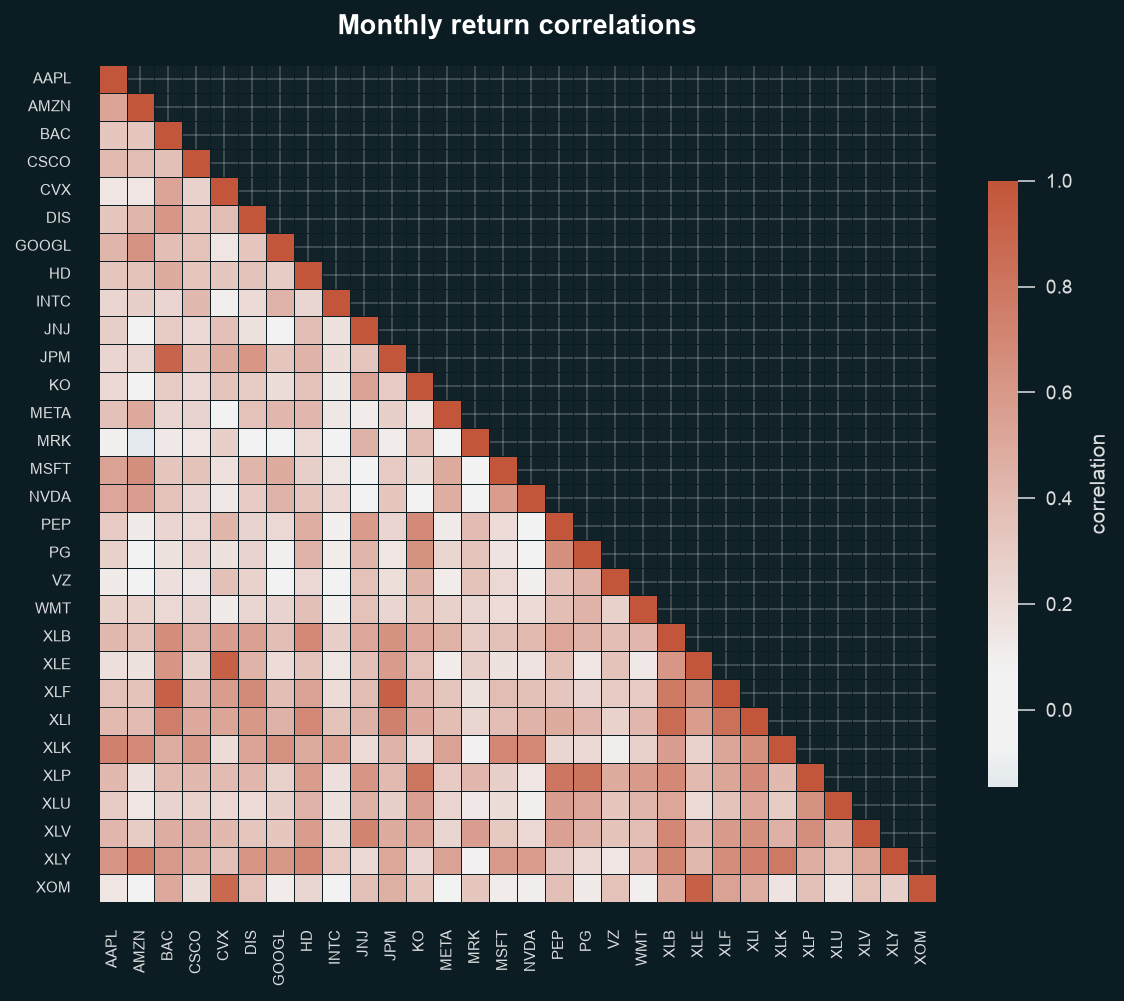

In [2]:
display(Image(filename=viz.plot_correlation(
    RETURNS[PRIMARY], OUTPUT_DIR / "correlation.png"
)))

## 3. Stage 1: portfolio choice and estimation error

The Mutual Fund Theorem says every efficient portfolio mixes the risk free asset
with the tangency portfolio. We estimate its inputs and compare with the index an
investor could buy.

### (1a) Summary statistics

In [3]:
PORTFOLIO = {
    u: run_portfolio_analysis(
        RETURNS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        comparison=load_value_weights(
            universe=u, assets=RETURNS[u].columns, dates=RETURNS[u].index
        ),
        comparison_label="value weights",
        output_dir=OUTPUT_DIR / u,
    )
    for u in UNIVERSES
}
PORTFOLIO[PRIMARY].summary

,mean (ann.),vol (ann.),sharpe (ann.),min month,max month
AAPL,0.292,0.272,0.985,-0.181,0.217
AMZN,0.233,0.312,0.670,-0.238,0.273
BAC,0.202,0.286,0.626,-0.250,0.285
CSCO,0.186,0.249,0.655,-0.155,0.316
CVX,0.153,0.285,0.453,-0.224,0.273
DIS,0.068,0.306,0.146,-0.186,0.249
GOOGL,0.253,0.270,0.852,-0.179,0.338
HD,0.145,0.229,0.530,-0.151,0.189
INTC,0.224,0.532,0.377,-0.354,1.141
JNJ,0.124,0.173,0.585,-0.122,0.144



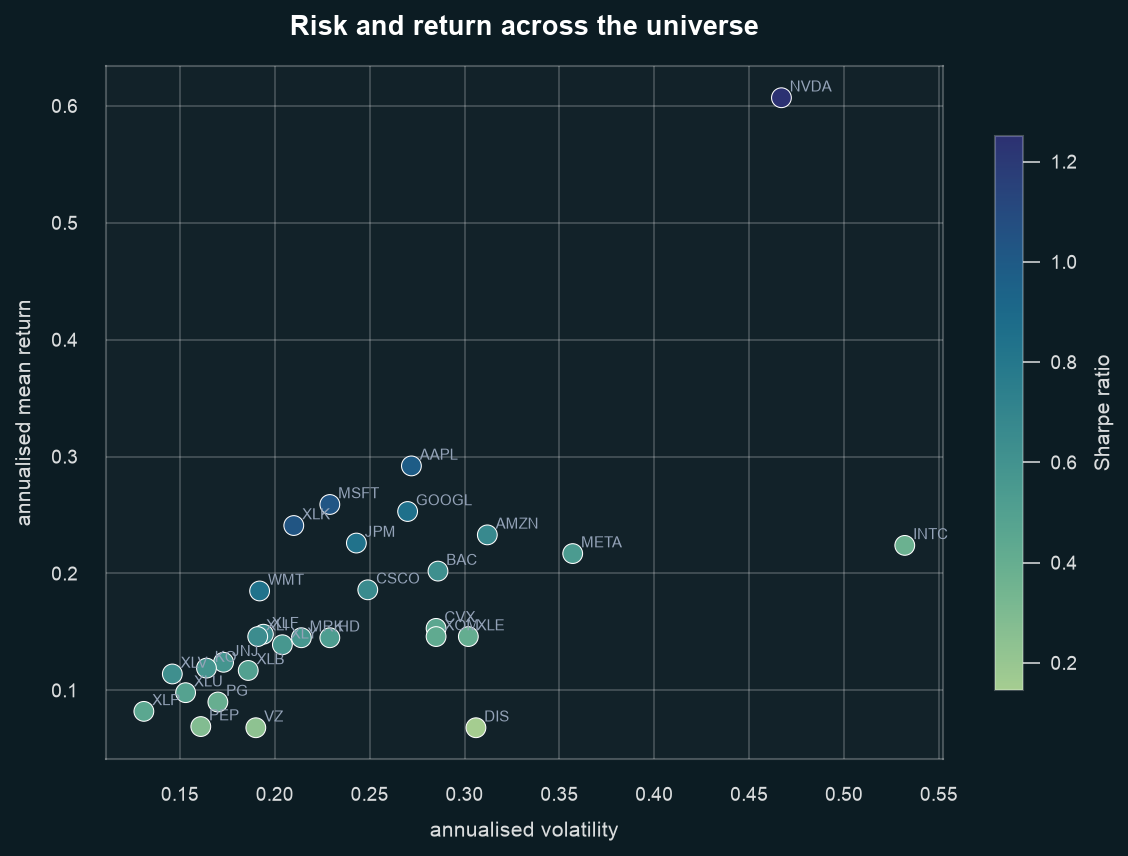

In [4]:
display(Image(filename=viz.plot_risk_return(
    PORTFOLIO[PRIMARY].summary, OUTPUT_DIR / "risk_return.png"
)))

**Takeaway.** Annualised means range from 7% to 61% and volatilities from 13% to
53%, a spread wide enough to make any long-only optimiser look decisive. The means
are the least reliable inputs: they move with the sample window far more than the
volatilities do, so a portfolio built to chase them is largely chasing noise.


### (1b) Tangency weights versus value weights


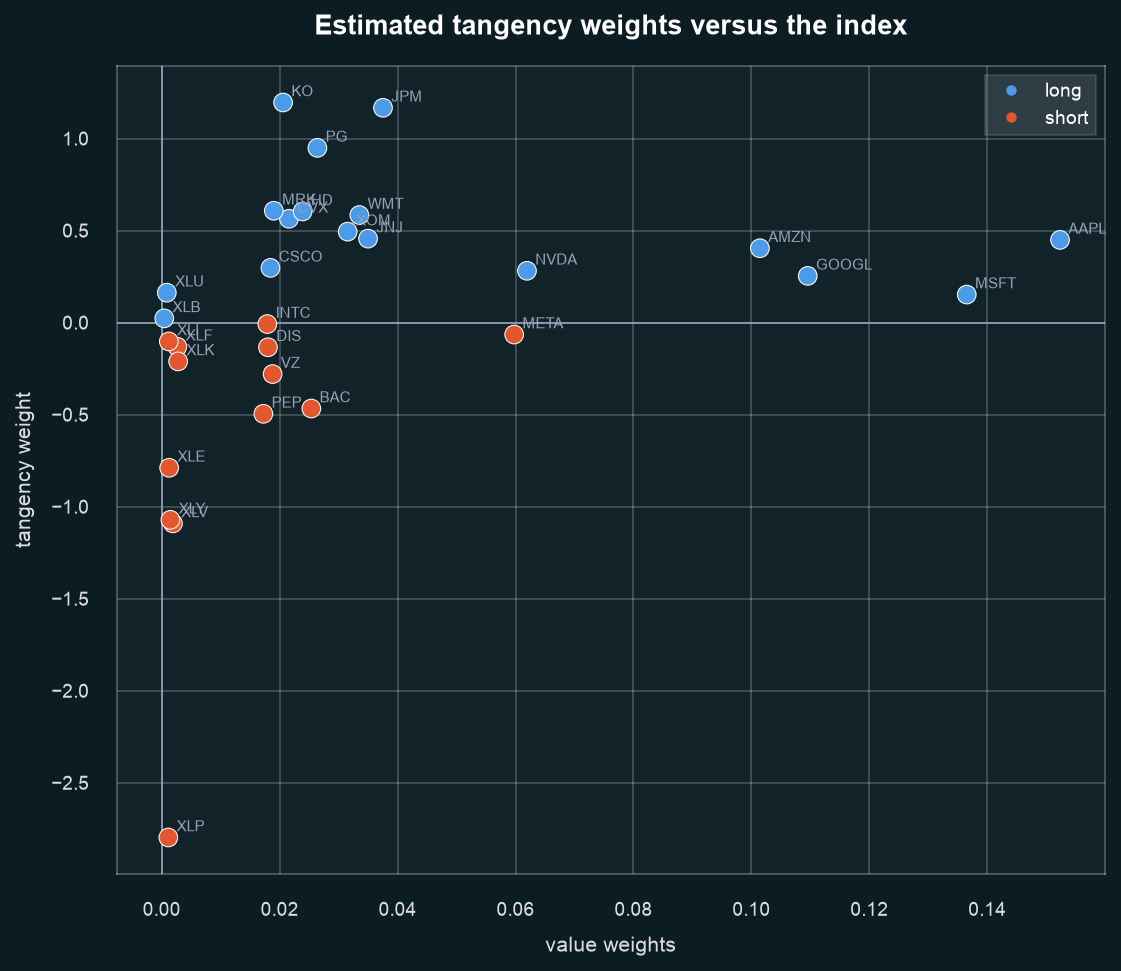

In [5]:
display(Image(filename=PORTFOLIO[PRIMARY].output_paths["weights"]))

In [6]:
w = PORTFOLIO[PRIMARY].weights
w.loc[w["tangency"].abs().sort_values(ascending=False).index].head(6).round(3)

,tangency,comparison
XLP,-2.797,0.001
KO,1.196,0.021
JPM,1.167,0.038
XLV,-1.091,0.002
XLY,-1.072,0.001
PG,0.949,0.026


**Takeaway.** Inverting a noisy covariance matrix turns estimation error into
extreme positions: the tangency portfolio shorts one US name by 280% and takes
gross exposure of 16 times the capital it manages. Nothing in the data justifies
those holdings - they are the arithmetic of an inverse applied to inputs we cannot
measure precisely.


### (1c) How stable are the weights?

In [7]:
print(f"first and second half weight correlation: {PORTFOLIO[PRIMARY].weight_correlation:.2f}")
PORTFOLIO[PRIMARY].drift

first and second half weight correlation: 0.35


,first half,second half,full sample
AAPL,0.127,1.346,0.449
AMZN,-0.043,0.111,0.404
BAC,-0.110,-2.978,-0.467
CSCO,0.285,0.508,0.297
CVX,0.572,-0.071,0.564
DIS,0.223,-0.049,-0.134
GOOGL,0.172,0.691,0.254
HD,0.234,1.416,0.604
INTC,0.049,0.178,-0.008
JNJ,-0.297,1.470,0.456



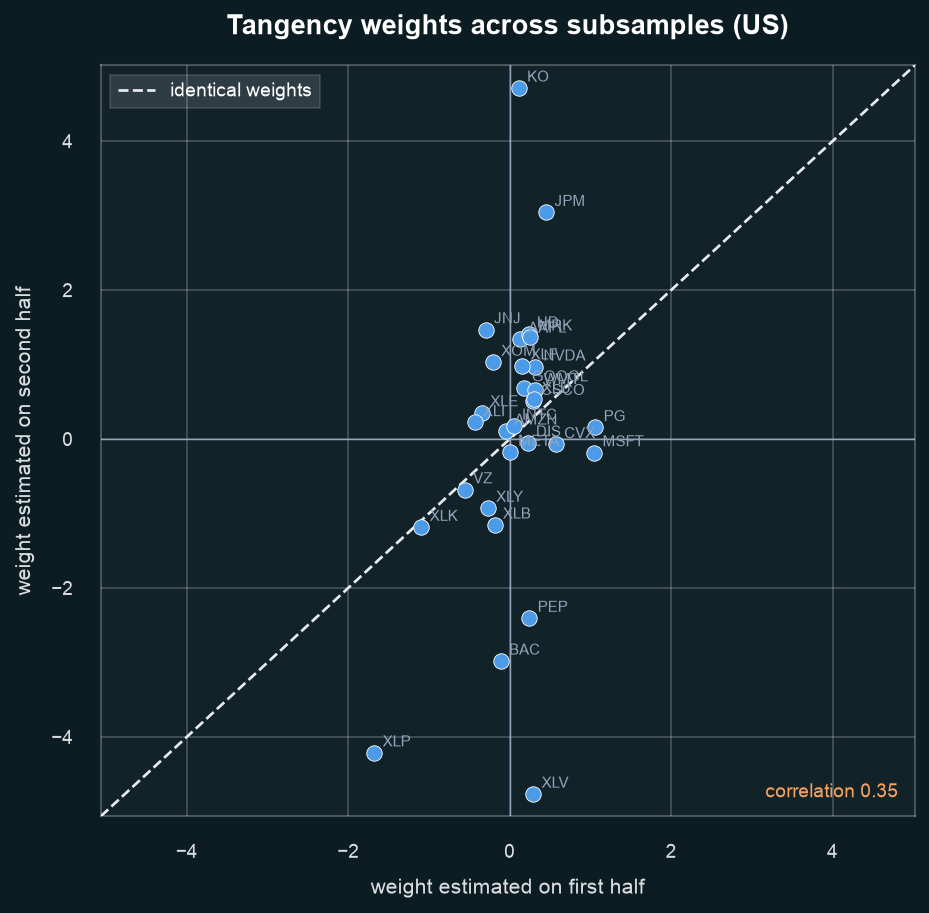

In [8]:
display(Image(filename=viz.plot_weight_drift(
    PORTFOLIO[PRIMARY].drift, OUTPUT_DIR / "weight_drift.png", label=PRIMARY
)))

**Takeaway.** Re-estimating on each half of the sample produces weights that
correlate at only 0.35. A portfolio whose holdings hardly resemble their own
other-half estimates is not a strategy: the large positions are sampling noise, and
an investor who held the full-sample version would be trading on accidents of the
window.


### Across markets

In [9]:
pd.DataFrame(
    {
        u: {
            "assets": RETURNS[u].shape[1],
            "largest absolute tangency weight": float(PORTFOLIO[u].most_extreme_weight),
            "half sample weight correlation": float(PORTFOLIO[u].weight_correlation),
        }
        for u in UNIVERSES
    }
).T.round(3)

,assets,largest absolute tangency weight,half sample weight correlation
us,30.0,2.797,0.354
sg,29.0,0.796,-0.104


**Takeaway.** Singapore is worse, at -0.10: the weight estimated on the first half
tells you almost nothing about the second. Two different markets agreeing that the
estimates are unstable is stronger evidence than either alone - the problem is the
method, not the sample.


### (1d) Taming the tangency portfolio

Two standard fixes reduce the extremes: a no-short constraint, and shrinkage of
both the covariance and the means.

In [10]:
from goldman.analysis.robustness import LABELS, run_robustness_analysis

FIXES = run_robustness_analysis(
    RETURNS[PRIMARY],
    rf=risk_free_series(PRIMARY, RETURNS[PRIMARY].index),
    output_dir=OUTPUT_DIR / PRIMARY,
    label=PRIMARY,
)
FIXES.diagnostics.rename(index=LABELS)[
    ["max weight", "min weight", "shorts", "gross leverage", "out of sample Sharpe"]
]

,max weight,min weight,shorts,gross leverage,out of sample Sharpe
unconstrained,1.196,-2.797,13.0,16.286,0.686
no short,0.201,0.000,0.0,1.000,0.814
shrunk,0.119,-0.055,6.0,1.351,0.857
"shrunk, no short",0.111,0.000,0.0,1.000,0.948



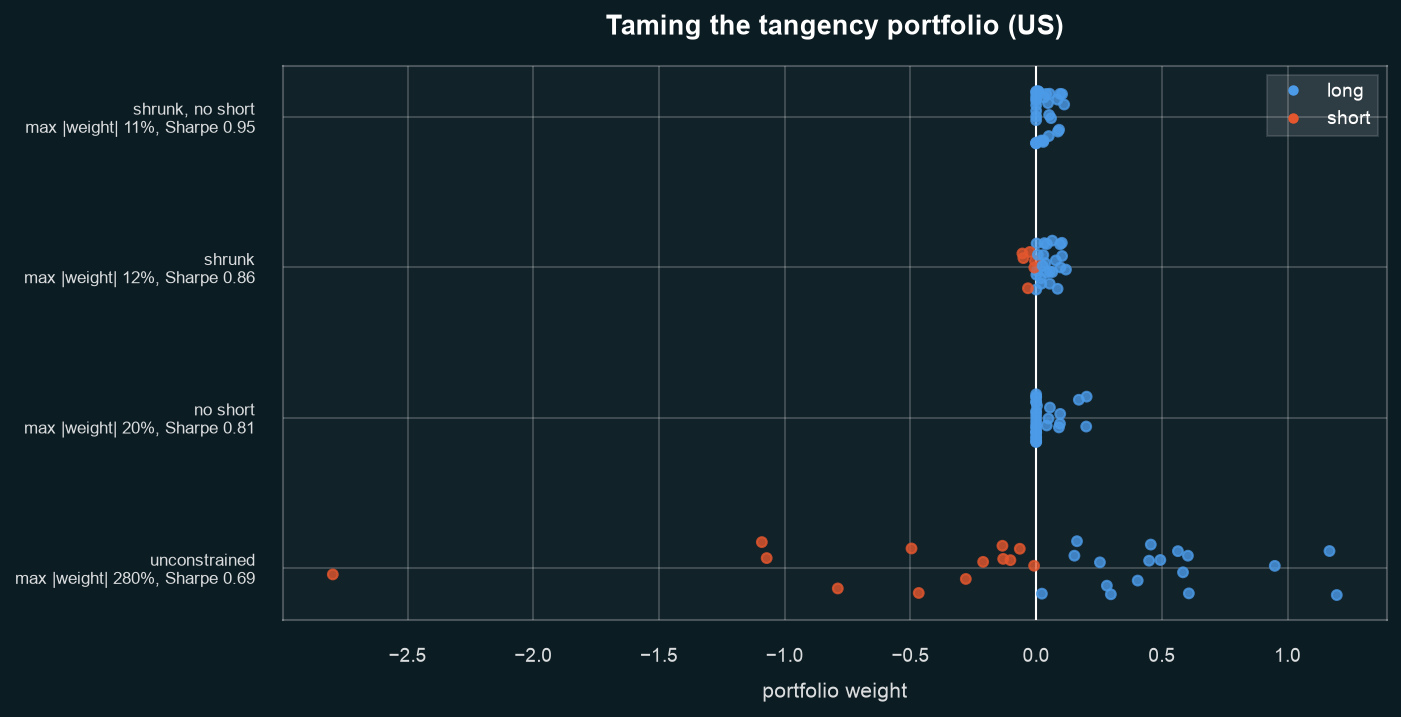

In [11]:
display(Image(filename=FIXES.output_paths["chart"]))

**Takeaway.** The fixes are not cosmetic. A no-short constraint and shrinkage of
both the covariance and the means bring the largest position down from 280% to 11%
and gross leverage from 16x to 1.0x, while out-of-sample Sharpe rises from 0.69 for
the raw tangency to 0.95 for the shrunk, long-only version. Restraining the
optimiser costs nothing in return here and removes positions no committee would
approve.


## 4. Stage 2: the CAPM and the empirical SML

Stage 1 asked what an optimizer would hold. Stage 2 asks how returns line up
across assets. The CAPM predicts

$$R_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(R_{M,t} - R_{f,t}) + \varepsilon_{i,t},$$

with nothing left over. We estimate it per asset and test jointly whether the
alphas are zero. With 30 assets, one or two values of |t| above 2 are expected by
chance, so the joint test carries the weight.

### (2a) Security characteristic lines

In [12]:
CAPM = {u: run_capm_analysis(RETURNS[u], universe=u, output_dir=OUTPUT_DIR) for u in UNIVERSES}
CAPM[PRIMARY].table[["beta", "alpha", "t_alpha", "p_alpha", "r_squared", "n"]].round(3)

,beta,alpha,t_alpha,p_alpha,r_squared,n
asset,,,,,,
AAPL,1.141,0.001,0.112,0.911,0.535,119
AMZN,1.417,-0.010,-1.777,0.078,0.631,119
BAC,0.953,-0.003,-0.491,0.624,0.339,119
CSCO,0.773,-0.001,-0.191,0.849,0.295,119
CVX,0.575,-0.000,-0.025,0.980,0.124,119
DIS,1.035,-0.016,-2.288,0.024,0.351,119
GOOGL,1.119,-0.002,-0.416,0.678,0.527,119
HD,0.693,-0.003,-0.560,0.577,0.279,119
INTC,1.243,-0.007,-0.507,0.613,0.167,119



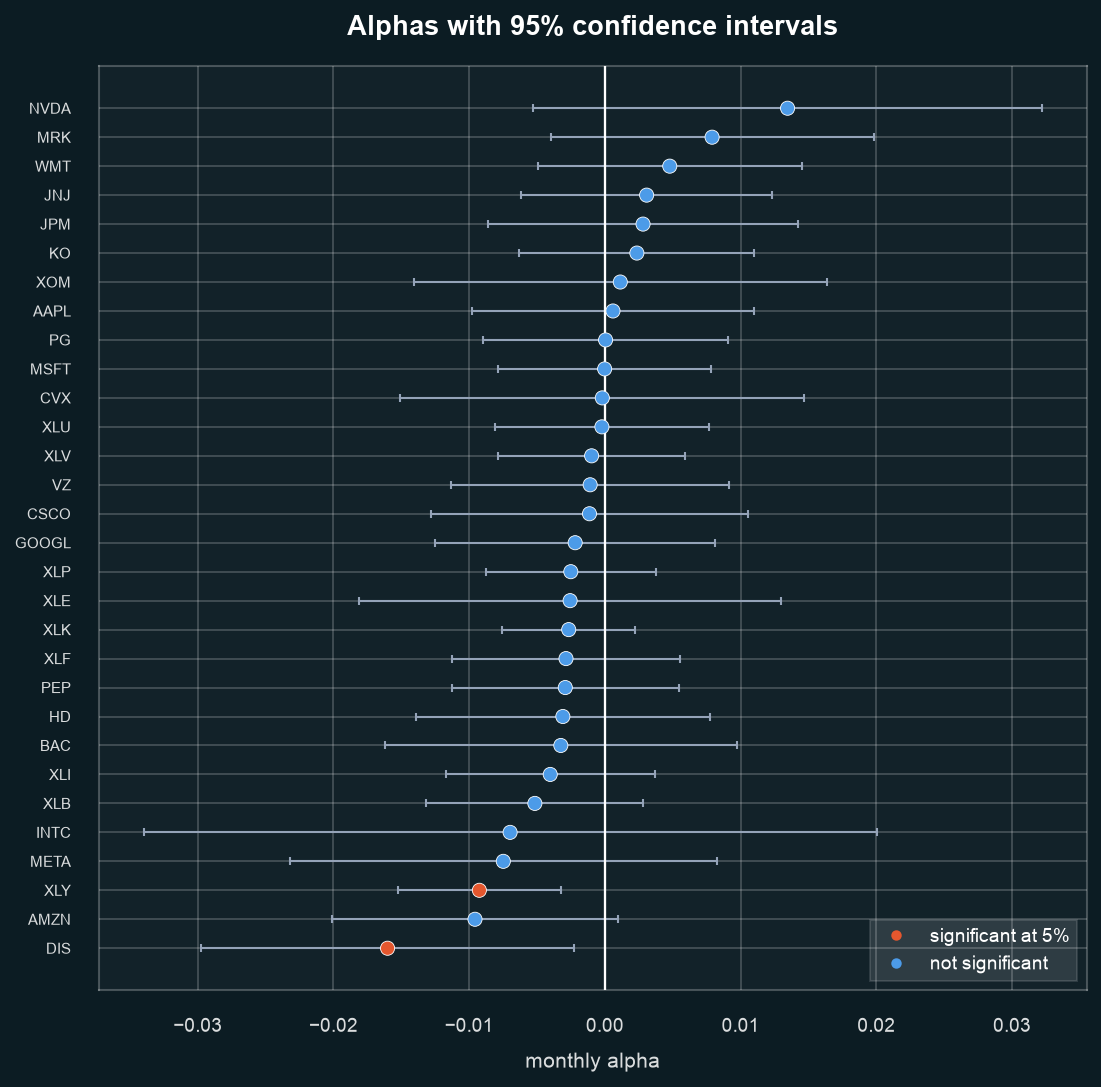

In [13]:
display(Image(filename=viz.plot_alpha_intervals(
    CAPM[PRIMARY].table, OUTPUT_DIR / "alpha_intervals.png"
)))

**Takeaway.** Betas are estimated precisely - the market factor explains a large
share of each name's variance and the standard errors are small - while alphas are
noisy: only 2 of 30 assets reach |t| > 2, and about 1.5 are expected by chance
alone. The market prices systematic risk tightly; it says much less about the
leftover average return.


### (2b) The empirical SML

US



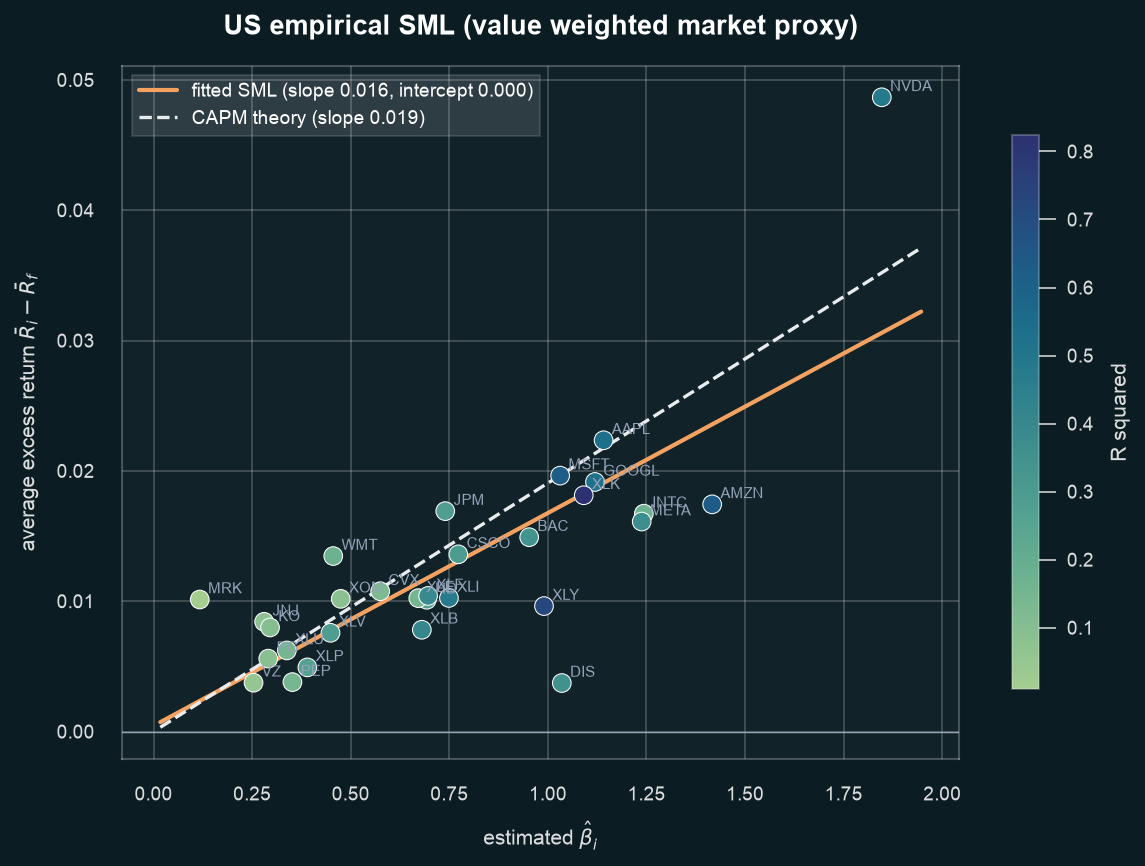

SG



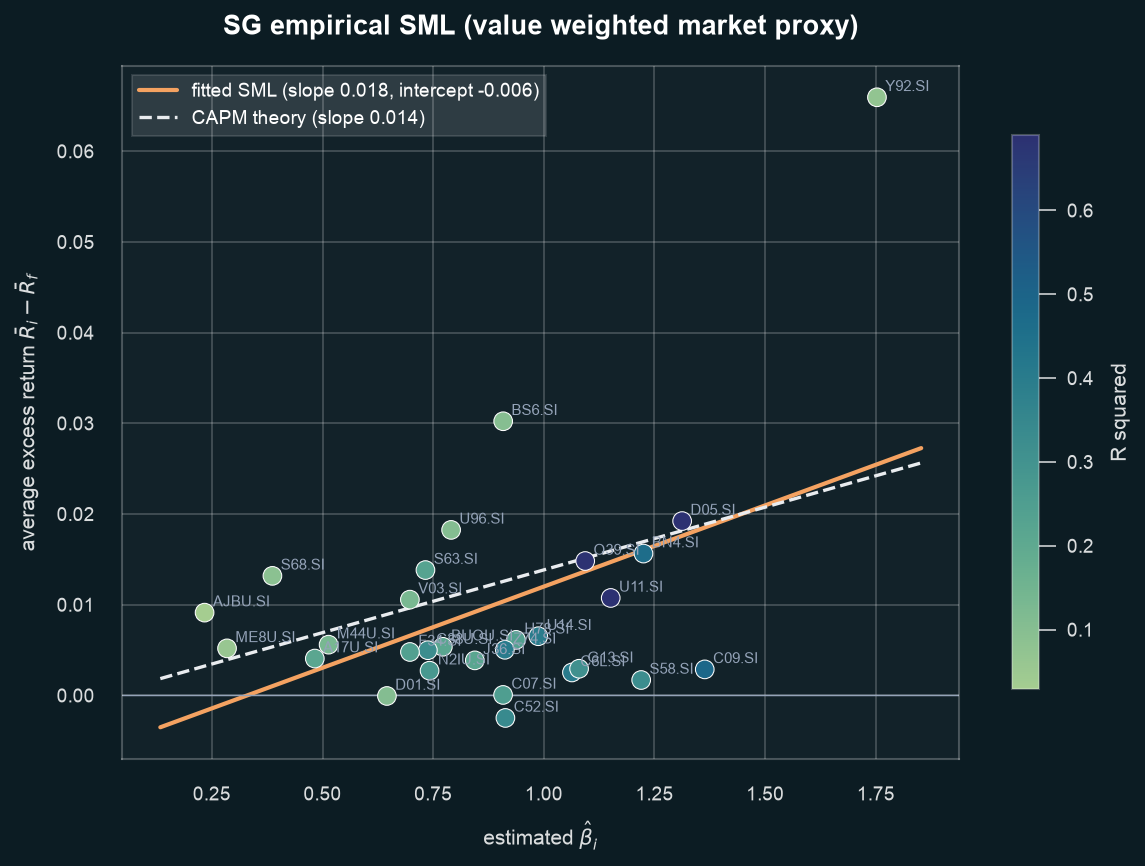

In [14]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=CAPM[u].output_paths["sml"]))

**Takeaway.** The empirical SML is flatter than theory in the US and steeper in
Singapore, so neither matches the line through the origin. The US scatter also
hugs its fitted line far more closely than Singapore's, which says the market
factor organises US risk well and Singapore risk poorly.


### (2c) Are all alphas zero?

**The GRS p value** is the probability of seeing alphas this large if every true
alpha were zero, so a value below 0.05 rejects the CAPM.

In [15]:
pd.DataFrame(
    {
        u: {
            "assets": int(c.fit.n),
            "alphas p<0.05": int((c.table["p_alpha"] < 0.05).sum()),
            "expected by chance": round(0.05 * len(c.table), 1),
            "GRS F": c.grs["f_stat"],
            "GRS p": c.grs["p_value"],
        }
        for u, c in CAPM.items()
    }
).T.round(3)

,assets,alphas p<0.05,expected by chance,GRS F,GRS p
us,30.0,2.0,1.5,1.008,0.469
sg,29.0,6.0,1.5,1.461,0.091



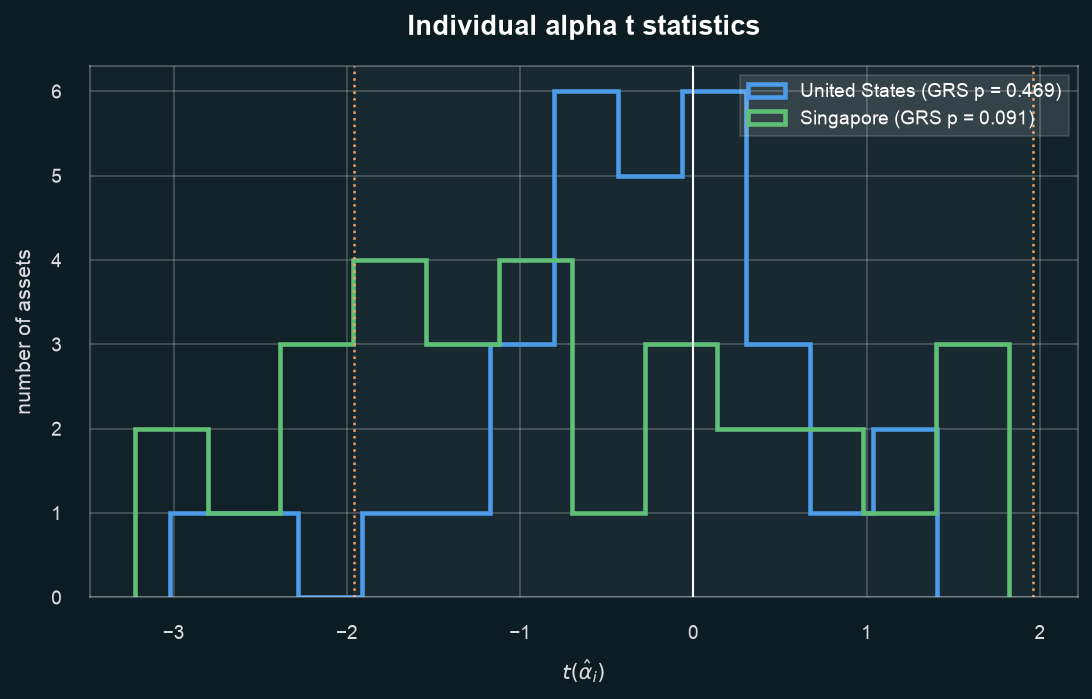

In [16]:
display(Image(filename=viz.plot_grs(CAPM, OUTPUT_DIR / "grs.png")))

**Takeaway.** The US cannot reject zero alphas (GRS p = 0.47) with 2 of 30
individually significant; Singapore is marginal (p = 0.09) with 6 of 29. Read
together, the US is consistent with the CAPM and Singapore is a warning that the
joint test, not the count of stars, is the one that matters.


### (2d) Fitted versus theoretical SML

In [17]:
pd.DataFrame(
    {
        u: {
            "fitted slope": c.fit.slope,
            "theoretical slope": c.fit.theoretical_slope,
            "fitted intercept": c.fit.intercept,
            "cross sectional R2": c.fit.r_squared,
        }
        for u, c in CAPM.items()
    }
).T.round(4)

,fitted slope,theoretical slope,fitted intercept,cross sectional R2
us,0.0163,0.0191,0.0004,0.6100
sg,0.0179,0.0138,-0.0059,0.2166



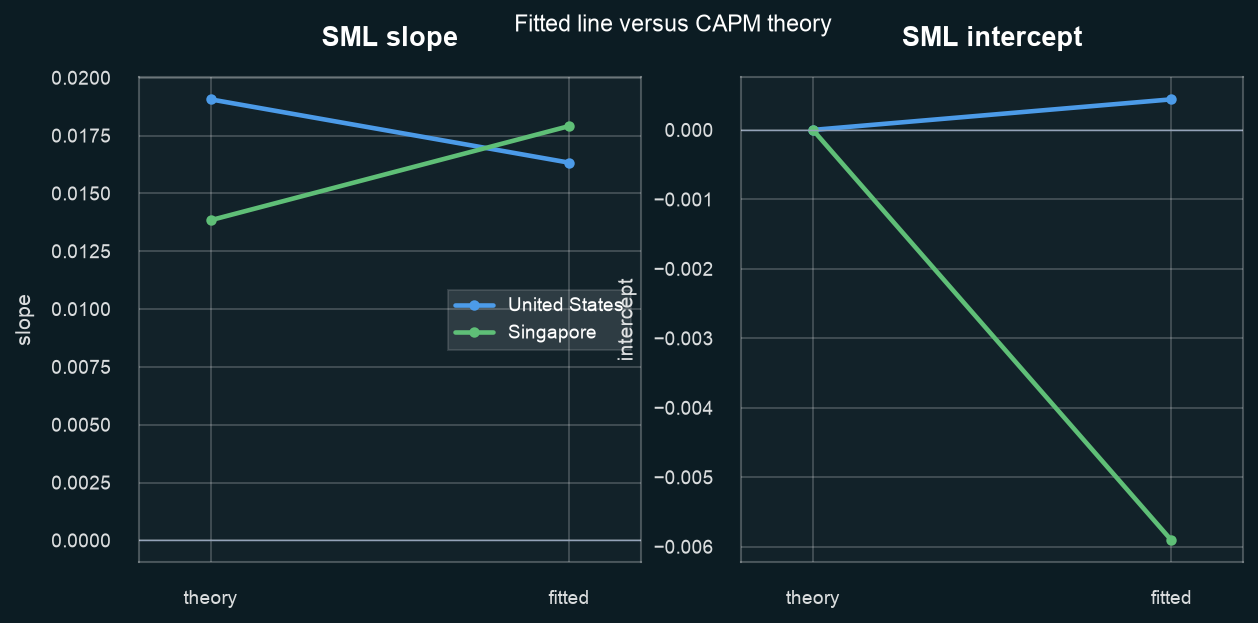

In [18]:
display(Image(filename=viz.plot_sml_fit(CAPM, OUTPUT_DIR / "sml_fit.png")))

**Takeaway.** The US slope is too flat (0.016 against a theoretical 0.019) and its
intercept is essentially zero, while Singapore's slope is too steep (0.018 against
0.014) with a negative intercept of -0.006. Theory wants a zero intercept and a
slope equal to the average market excess return; the US misses on the slope,
Singapore on both, and their cross-sectional fits differ (R squared 0.61 versus
0.22).


## 5. Stage 3: factors

Stage 2 left the market as the only source of common variation. Stage 3 adds size
and momentum. For the US we use Ken French's factors as the external benchmark;
because Singapore has no free factor library, we build the size and momentum
factors ourselves and run them on both markets. Every model is estimated on one
common sample (the months where all factors exist) and, within a market, against
the same market factor, so an alpha that shrinks cannot be an artefact of a
shorter window or a different proxy.


### (3a) How the factors are built

**Size (SMB).** Each month we rank the assets by market capitalisation at the
*previous* month end, using the committed point-in-time value weights so the sort
never sees the month it is predicting. We go long the small-cap third and short
the large-cap third, equal-weighted, and take the difference — the Fama and
French 30/40/30 convention, which drops the middle third.

**Momentum (WML).** We rank by the compounded return from month t-12 to t-2, the
standard 12-1 formation that skips the most recent month to avoid short-term
reversal, and go long the winners and short the losers. The two factors are built
from the same returns they help explain; that is deliberate, and it is why a
factor can mechanically absorb cross-sectional variation.



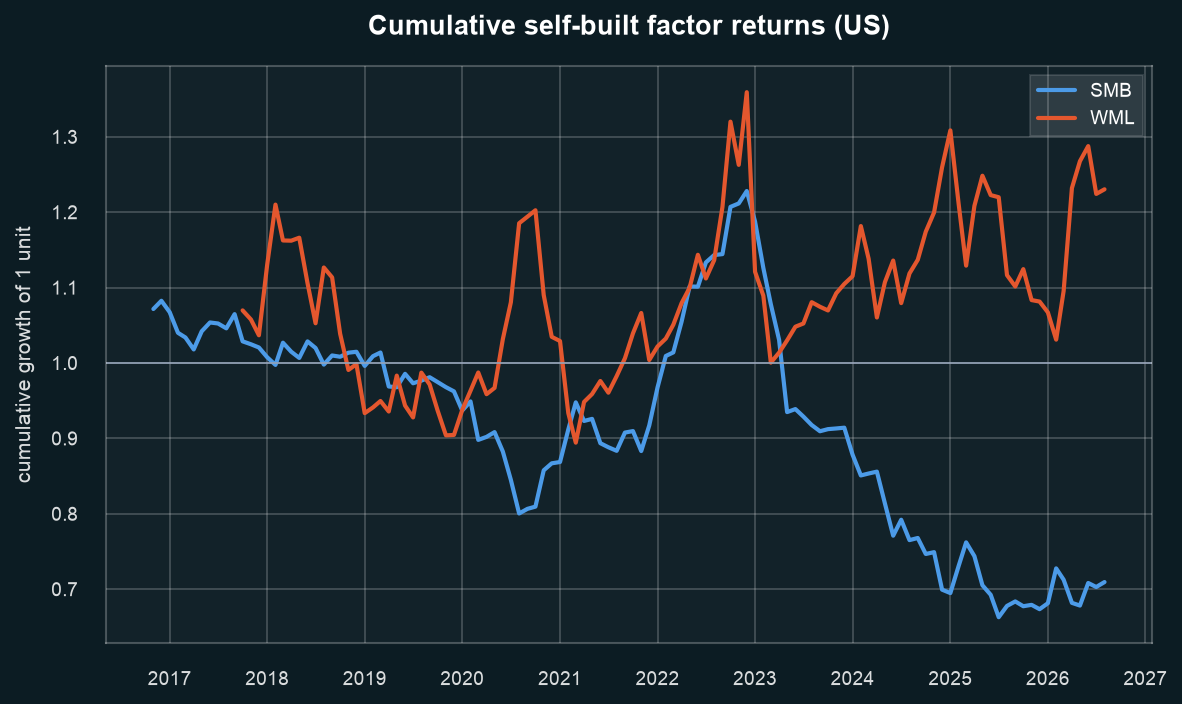

,months,SMB mean (ann.),SMB vol (ann.),WML mean (ann.),WML vol (ann.)
us,118.0,-0.03,0.101,0.037,0.165
sg,118.0,-0.06,0.128,0.179,0.166


In [19]:
from goldman.analysis import build_self_factors

BUILT = {u: build_self_factors(RETURNS[u], universe=u) for u in UNIVERSES}
display(Image(filename=viz.plot_factor_cumulative(
    BUILT[PRIMARY],
    OUTPUT_DIR / "factor_cumulative.png",
    title=f"Cumulative self-built factor returns ({PRIMARY.upper()})",
)))
pd.DataFrame(
    {
        u: {
            "months": int(BUILT[u]["SMB"].notna().sum()),
            "SMB mean (ann.)": BUILT[u]["SMB"].mean() * 12,
            "SMB vol (ann.)": BUILT[u]["SMB"].std() * np.sqrt(12),
            "WML mean (ann.)": BUILT[u]["WML"].mean() * 12,
            "WML vol (ann.)": BUILT[u]["WML"].std() * np.sqrt(12),
        }
        for u in UNIVERSES
    }
).T.round(3)


**Takeaway.** The US self-built momentum earns 3.7% a year and size loses 3.0%;
Singapore momentum earns a striking 17.9% while its size spread loses 6.0%. The
spreads are large but noisy, and because the universe is built from mega-caps the
"small" leg is barely small - the self-built size factor is a weak proxy at best,
which matters when we read what it absorbs.


### (3b) Alphas before versus after factors

For each universe we run the CAPM and then the factor models on the same market
factor and the same common sample. The US uses the Fama and French market factor
throughout; Singapore uses its own value-weighted index because its factors are
self-built.


In [20]:
from goldman.analysis import run_factor_analysis
from goldman.data import market_excess_returns

FF3 = load_ff3()
FF3.index = FF3.index.to_timestamp()

market_sg = market_excess_returns(RETURNS["sg"], universe="sg", method="value_weighted")
market_sg.name = "Mkt-RF"

FACTOR_MODELS = {
    "us": {
        "CAPM": FF3[["Mkt-RF"]],
        "FF3": FF3[["Mkt-RF", "SMB", "HML"]],
        "FF3 + momentum": pd.concat(
            [FF3[["Mkt-RF", "SMB", "HML"]], BUILT["us"][["WML"]]], axis=1
        ),
        "Self-built SMB + WML": pd.concat(
            [FF3[["Mkt-RF"]], BUILT["us"][["SMB", "WML"]]], axis=1
        ),
    },
    "sg": {
        "CAPM": market_sg.to_frame(),
        "Self-built SMB + WML": pd.concat([market_sg, BUILT["sg"][["SMB", "WML"]]], axis=1),
    },
}
FACTORS = {
    u: run_factor_analysis(
        RETURNS[u],
        universe=u,
        models=FACTOR_MODELS[u],
        rf=risk_free_series(u, RETURNS[u].index),
        output_dir=OUTPUT_DIR,
    )
    for u in UNIVERSES
}
pd.concat({u: FACTORS[u].summary for u in UNIVERSES}).round(4)


assets  mean |alpha|  max |alpha|  alphas p<0.05  mean R2   GRS F   GRS p
us CAPM                    30.0        0.0045       0.0253            1.0   0.3800  1.0152  0.4630
   FF3                     30.0        0.0040       0.0240            1.0   0.4820  1.0355  0.4380
   FF3 + momentum          30.0        0.0040       0.0234            1.0   0.4976  0.9998  0.4834
   Self-built SMB + WML    30.0        0.0046       0.0200            1.0   0.4758  1.0091  0.4713
sg CAPM                    29.0        0.0088       0.0433            8.0   0.2949  1.8019  0.0215
   Self-built SMB + WML    29.0        0.0064       0.0209            4.0   0.3893  2.0858  0.0059


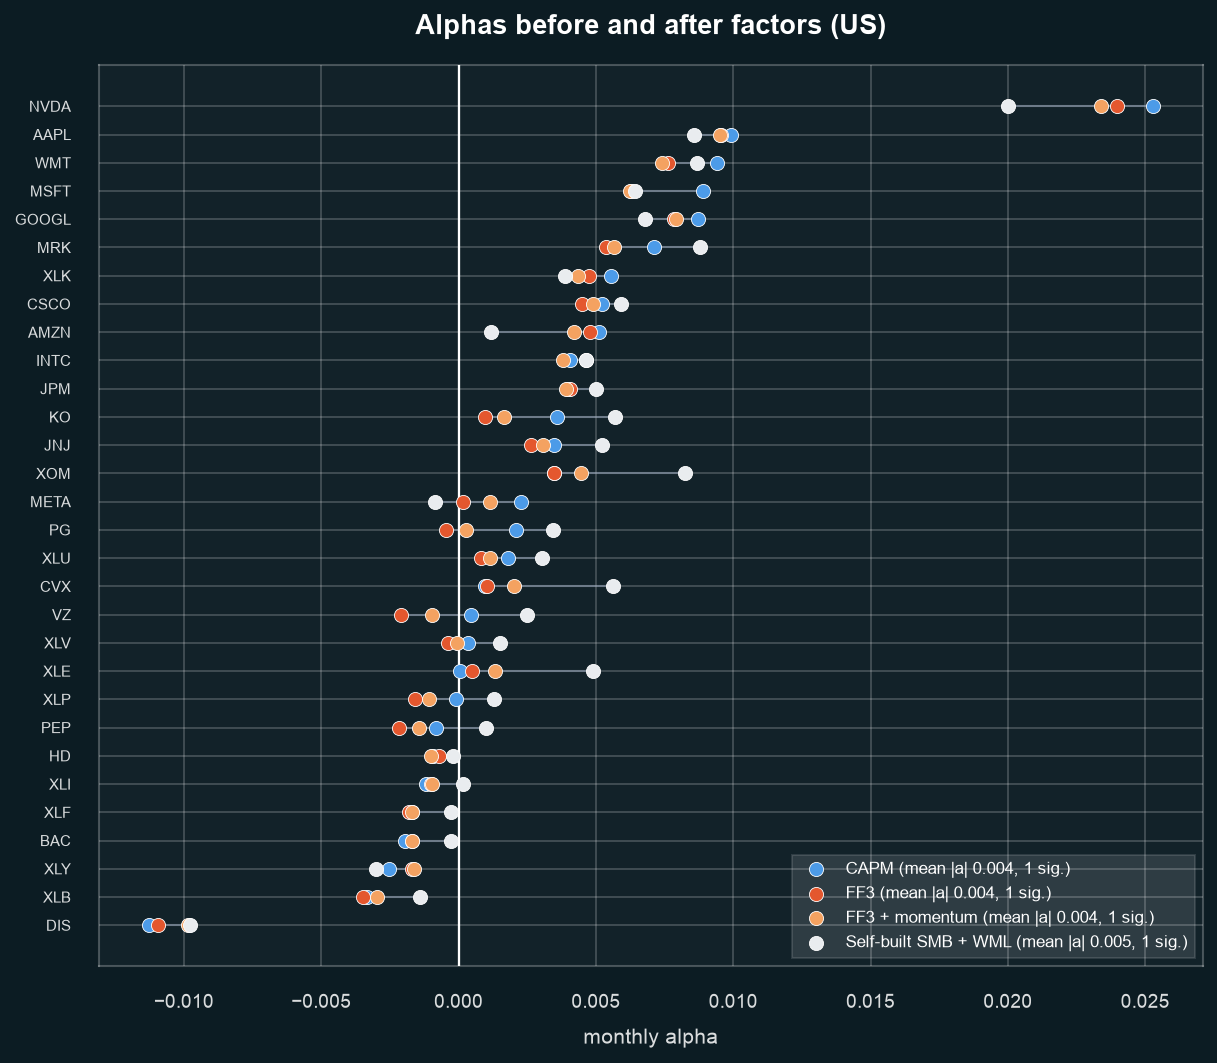

In [21]:
display(Image(filename=FACTORS[PRIMARY].output_paths["chart"]))


**Takeaway.** In the US the CAPM already leaves little to explain: only NVDA is
significant, no joint test rejects, and adding factors barely moves the average
alpha. In Singapore the factors shrink the largest alphas by roughly half (max
|alpha| 4.3% to 2.1% a month) and cut the significant count from 8 to 4, so size
and momentum absorb a real part of the Stage-2 anomaly rather than none of it.


### (3c) Which anomalies survive?

The table lists every asset whose alpha is significant before or after the
factors (`|t| > 2`).


In [22]:
for u in UNIVERSES:
    first, last = FACTORS[u].models[0], FACTORS[u].models[-1]
    t_first = FACTORS[u].tables[first]["t_alpha"]
    t_last = FACTORS[u].tables[last]["t_alpha"]
    flagged = (t_first.abs() > 2) | (t_last.abs() > 2)
    block = pd.DataFrame(
        {
            f"{first} alpha": FACTORS[u].alphas[first],
            f"{first} t": t_first,
            f"{last} alpha": FACTORS[u].alphas[last],
            f"{last} t": t_last,
        }
    )
    print(u.upper())
    display(block[flagged].round(4))


US


,CAPM alpha,CAPM t,Self-built SMB + WML alpha,Self-built SMB + WML t
asset,,,,
NVDA,0.0253,2.4032,0.02,2.166


SG


,CAPM alpha,CAPM t,Self-built SMB + WML alpha,Self-built SMB + WML t
asset,,,,
C07.SI,-0.0124,-2.0217,-0.0140,-2.1377
C09.SI,-0.0176,-3.2050,-0.0209,-4.0043
C52.SI,-0.0130,-2.7139,-0.0086,-1.7716
C6L.SI,-0.0117,-2.2437,-0.0060,-1.1243
G13.SI,-0.0158,-2.8582,-0.0112,-1.9401
S58.SI,-0.0148,-2.1211,-0.0072,-1.0549
S68.SI,0.0093,1.8727,0.0136,2.6736
U11.SI,-0.0062,-2.0703,-0.0043,-1.3613
U14.SI,-0.0101,-2.1272,-0.0107,-2.3281


**Verdict.** In the US there is nothing for the factors to absorb: NVDA is
positively significant before and after, and every joint test is comfortably
insignificant. In Singapore the self-built size and momentum factors absorb the
*level* of the Stage-2 anomaly — five of the eight CAPM alphas lose significance,
the worst falls from +4.3% to +0.5% a month (Y92), and the cross-sectional
average |alpha| falls from 0.88% to 0.64%. What survives is the joint rejection
itself: the GRS p value tightens from 0.02 to 0.006, because the factors shrink
the residual covariance faster than the alphas. A smaller alpha per asset and a
stronger joint test are not contradictory; they answer different questions.


## 6. Robustness: the market proxy


**Exhibit 3. The same assets, two market proxies.** Stage 2 re-estimated
with a value-weighted composite and with the Fama and French market factor.


In [23]:
ff3 = load_ff3()
PROXY = {
    m: run_capm_analysis(
        RETURNS[PRIMARY], universe=PRIMARY, method=m, ff3=ff3, output_dir=OUTPUT_DIR
    )
    for m in ["value_weighted", "ff_market"]
}
pd.DataFrame(
    {
        m: {
            "fitted slope": r.fit.slope,
            "theoretical slope": r.fit.theoretical_slope,
            "beta min": r.table["beta"].min(),
            "beta max": r.table["beta"].max(),
            "alphas p<0.05": int((r.table["p_alpha"] < 0.05).sum()),
            "GRS p": r.grs["p_value"],
        }
        for m, r in PROXY.items()
    }
).T.round(3)

,fitted slope,theoretical slope,beta min,beta max,alphas p<0.05,GRS p
value_weighted,0.016,0.019,0.117,1.847,2.0,0.469
ff_market,0.015,0.011,0.254,1.749,1.0,0.190



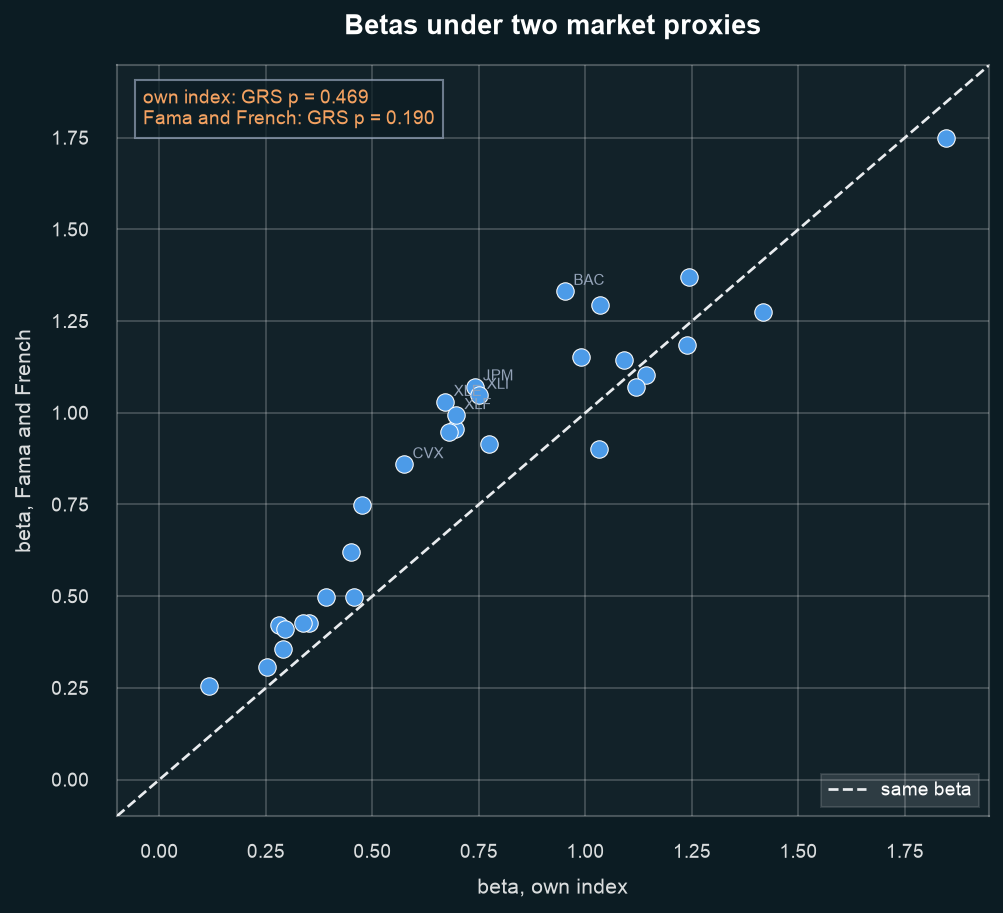

In [24]:
display(Image(filename=viz.plot_proxy_comparison(PROXY, OUTPUT_DIR / "proxy_comparison.png")))

**Takeaway.** Changing only the market proxy halves the GRS p value, from 0.47 to
0.19. The average beta rises from 0.75 to 0.88 and individual betas move by up to
0.38 even though the two proxies are strongly related; the headline number depends
on a choice we made, which is Roll's critique in miniature.


## 7. Stage 4: the memo to the investment committee

*This is the two-page memo Stage 4 asks for. It is written for a numerate but
busy reader and refers back to the exhibits rather than repeating them.*


### The recommendation: hold the index, not the tangency portfolio

The theorem tells us *how* to build the best portfolio, not *what* it is. Its
answer is the tangency portfolio, and to compute it we must supply expected
returns and a covariance matrix. Both are estimates from a finite sample, and the
tangency portfolio is unusually exposed to them: it inverts the covariance matrix,
so it places its largest bets exactly where the estimates are least stable, and it
scales those bets by expected returns, the noisiest input we have. The result is
less a portfolio than a restatement of the sample's accidents - concentrated,
long-short (it wants to short one US name by 280%), and barely recognisable from
one half of the data to the next.

That is why we would not fund it. Re-estimated each month from past data and
traded the following month (Section 8), it is the weakest rule we consider in both
markets and carries the deepest drawdown, while the index - which needs no
forecast at all - is the strongest. This is not a claim that markets are
efficient. It is the narrower and more defensible point that *our* estimates are
not good enough to support the concentrated positions the optimiser derives from
them.

So our recommendation is the value-weighted index. It is transparent, cheap,
diversified by construction, and it does not ask the committee to trust a
covariance matrix we know to be unreliable. If the committee will accept modest
estimation risk in exchange for a tilt, the sensible implementation is the
*shrunk, long-only* tangency: shrinking the inputs damps the noise, and the
no-short constraint stops the optimiser turning an estimate into a large negative
position. That keeps the spirit of the theory while refusing to bet the portfolio
on the parts of the data we trust least. What we would not do is hand the raw
tangency weights to a trader.


In [25]:
# Out-of-sample evidence: estimate the weights every month, trade the next.
from goldman.analysis import run_out_of_sample_analysis
from goldman.data import market_excess_returns

OOS = {
    u: run_out_of_sample_analysis(
        RETURNS[u],
        universe=u,
        rf=risk_free_series(u, RETURNS[u].index),
        index_returns=market_excess_returns(RETURNS[u], universe=u),
        output_dir=OUTPUT_DIR / u,
        label=u,
    )
    for u in UNIVERSES
}
pd.concat({u: OOS[u].summary for u in UNIVERSES}).round(3)


months  ann. mean  ann. vol  Sharpe  max drawdown
us index               59.0      0.210     0.191   1.096        -0.246
   equal_weight        59.0      0.130     0.146   0.896        -0.206
   unconstrained       59.0      0.339     0.752   0.451        -0.756
   long_only           59.0      0.151     0.183   0.828        -0.314
   shrunk              59.0      0.098     0.141   0.699        -0.263
   shrunk_long_only    59.0      0.109     0.138   0.793        -0.241
sg index               59.0      0.203     0.098   2.074        -0.082
   equal_weight        59.0      0.128     0.106   1.206        -0.112
   unconstrained       59.0      0.175     0.441   0.398        -0.632
   long_only           59.0      0.220     0.158   1.386        -0.152
   shrunk              59.0      0.152     0.128   1.186        -0.153
   shrunk_long_only    59.0      0.158     0.118   1.339        -0.118

**Takeaway.** Re-estimated every month and traded forward, the index is the
strongest rule in both markets once risk is accounted for (Sharpe 1.10 in the US,
2.07 in Singapore), the raw tangency the weakest (0.45 and 0.40) with by far the
deepest drawdowns, and even the best of the estimated rules, shrunk and long-only,
stays below the index on a risk-adjusted basis.


### Roll's critique: we test the proxy, not the CAPM

A CAPM test is never run against "the market". It is run against a stand-in we
choose, and the model requires that stand-in to be mean-variance efficient. Our
value-weighted index and Ken French's market factor are two proxies for the same
US market, but they are not the same portfolio. Swapping one for the other on the
same assets (Section 6) leaves the story intact and moves the evidence: individual
betas shift by up to 0.38, the alphas on some names move enough to change which
ones look significant, and the GRS p value halves. The direction of the finding is
stable; its strength is not.

That sensitivity is itself the finding. It means we cannot say the CAPM is true or
false from this exercise - only whether a particular proxy passes. Roll's critique
stops being an abstract caveat and becomes a description of our own results: the
number we report depends on a choice we made, and another reasonable choice would
have told a different story.


### The result we trust least

The self-built Singapore size factor. It is a long-short spread over roughly 29
large, liquid STI names, so the "small" leg is large by any real standard, and it
is built from the same returns it is asked to explain, so part of its
alpha-absorption is mechanical rather than economic. It is a legitimate robustness
result - it moves the numbers the way a genuine factor would - but we would not
claim it as evidence that size is priced in Singapore. The US result is the one we
trust most precisely because it is dull: against a value-weighted index the market
prices these mega-caps about as well as the CAPM says it should, and the factors
have almost nothing left to do.


## 8. Out-of-sample validation

*This is the test behind the memo's recommendation. Each strategy is re-estimated
every month on an expanding window of past data and then held for the single month
that follows, so no weight ever sees the return it is traded on. The value-weighted
index and 1/N need no estimation and are the benchmarks. The training window is
only five years, which gives the estimated portfolios every advantage a short
sample can offer - the test is generous to them, not to the index.*


US



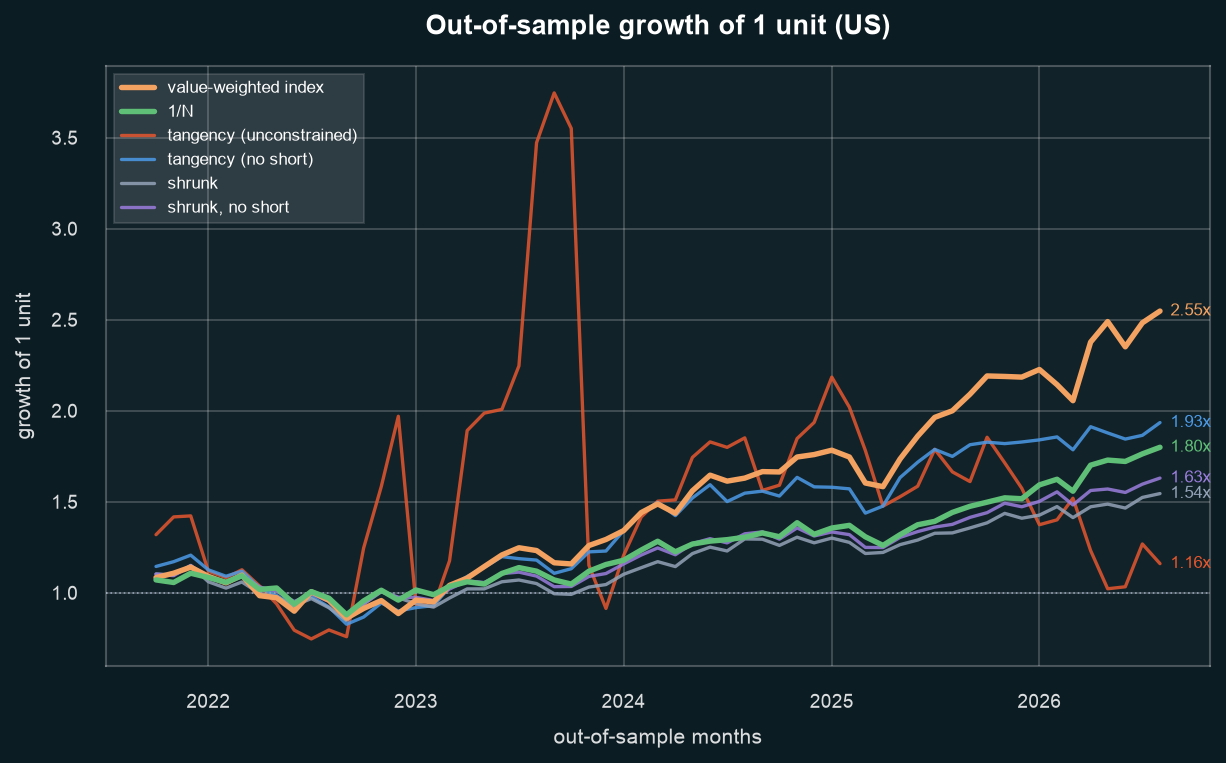

SG



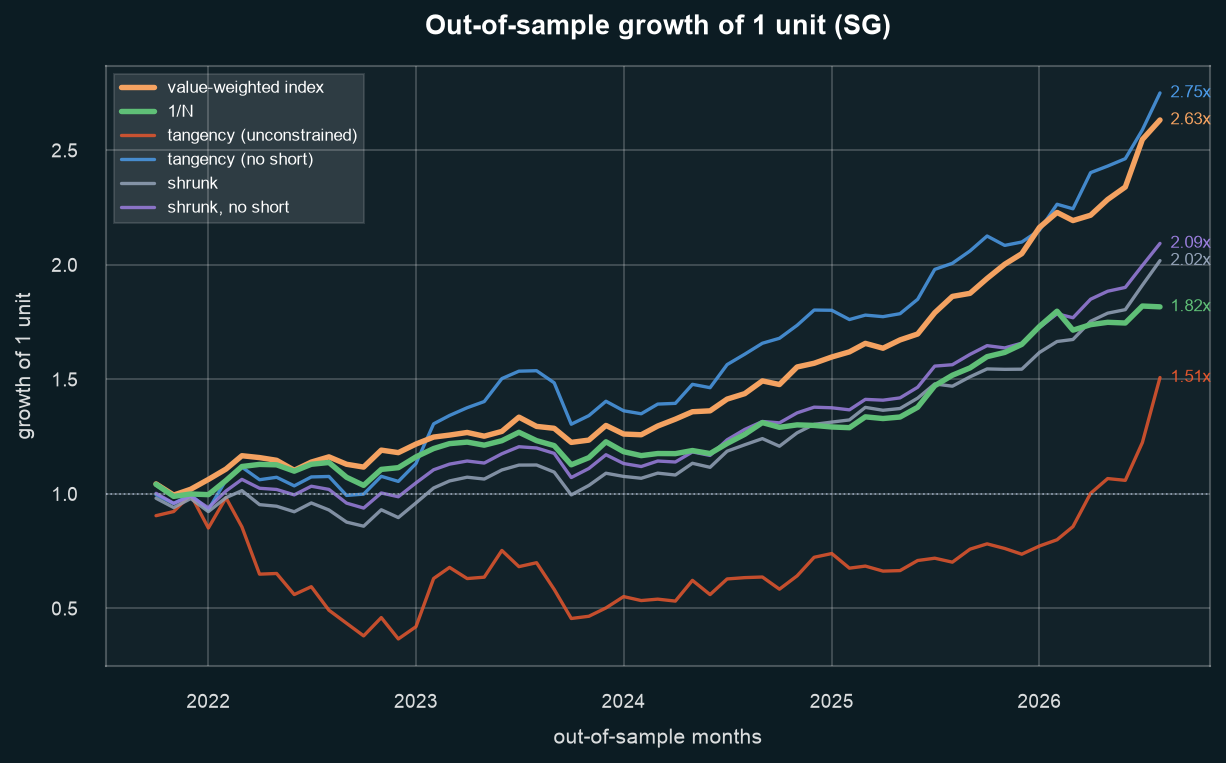

In [26]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=OOS[u].output_paths["growth"]))


**Takeaway.** The 59 out-of-sample months separate the rules. In the US the
index compounds to the largest gain (2.55 times the starting value) while the
unconstrained tangency ends near where it began (1.16x), after a spike to almost
4x and a fall back to earth; in Singapore the no-short tangency edges the index on
total growth (2.75x against 2.63x) but pays for it with roughly 60% more
volatility. Across both markets the unconstrained tangency is the worst on a
risk-adjusted basis and draws down the most, about -76% in the US and -63% in
Singapore - losses the optimiser never chose, but estimation error delivered.


US



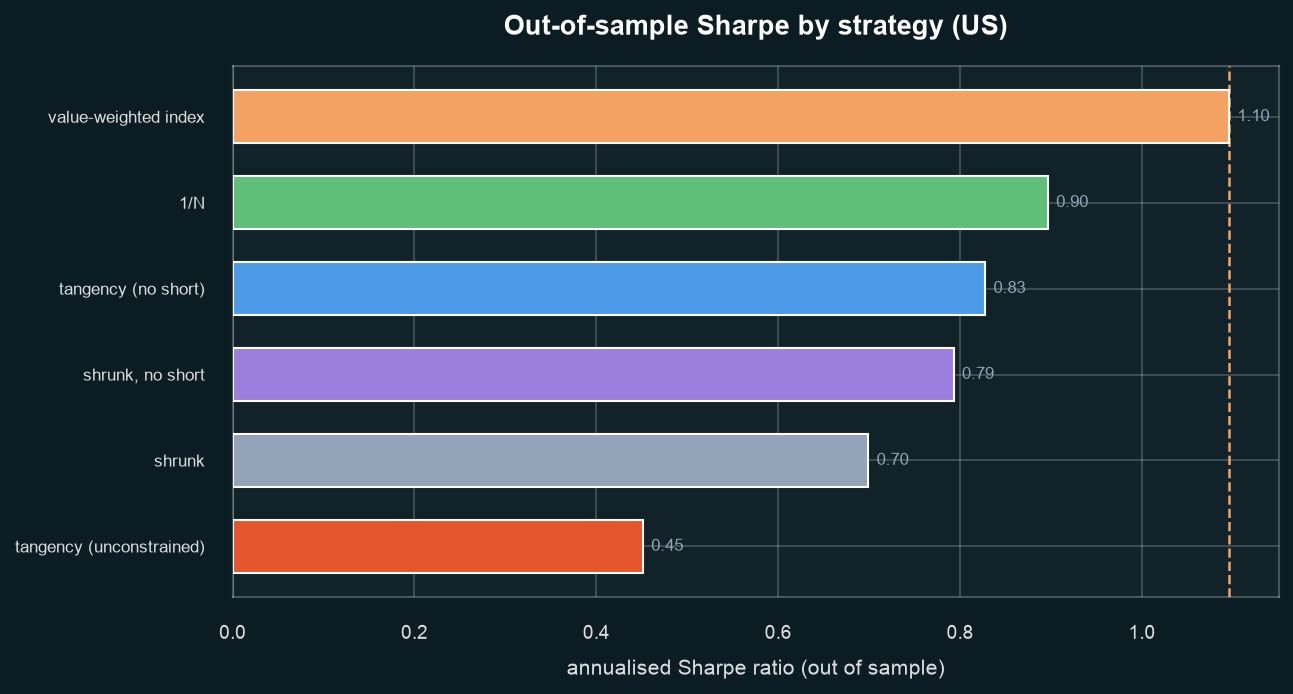

SG



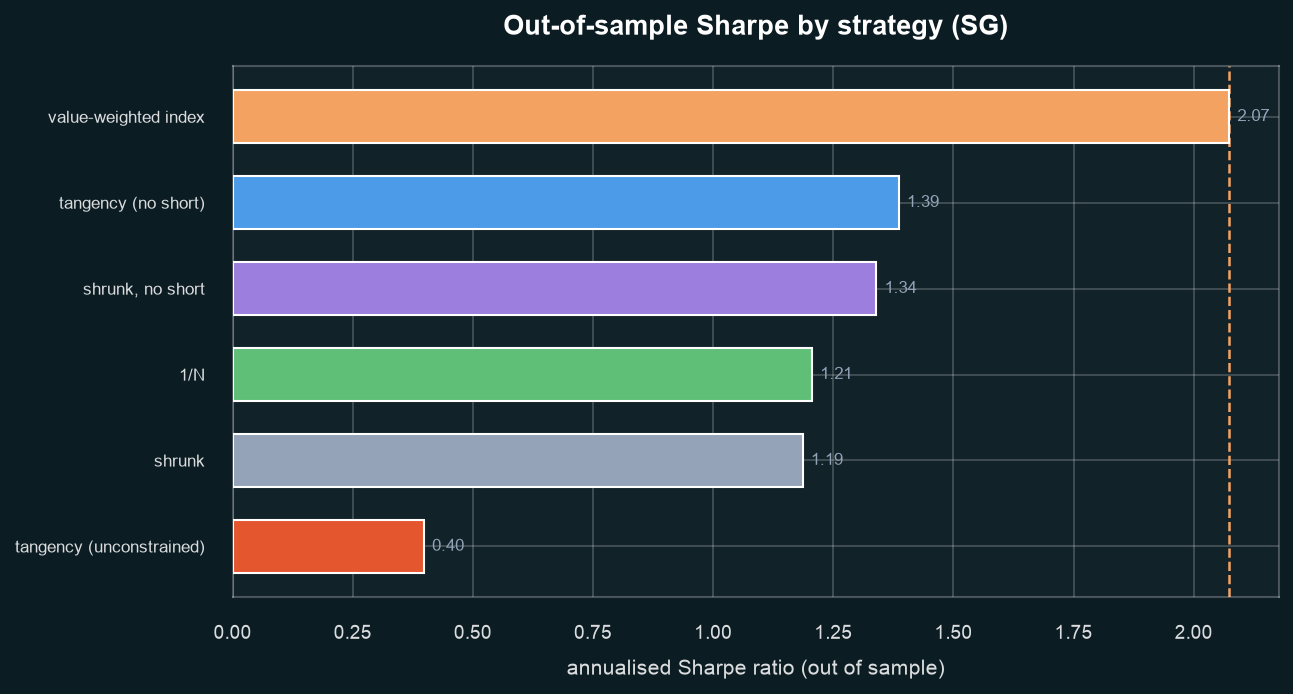

In [27]:
for u in UNIVERSES:
    print(u.upper())
    display(Image(filename=OOS[u].output_paths["sharpe"]))


**Verdict.** Rank the rules by Sharpe and the order is identical in both
markets: the index first (1.10 in the US, 2.07 in Singapore), the estimated
tangency last (0.45 and 0.40), and the shrunk, long-only variant the best of the
estimated rules (0.79 and 1.34) yet still short of the index. No single rule wins
on every dimension - the no-short and shrunk variants do cut the tail risk
sharply, and in Singapore the no-short portfolio even out-grows the index - but
none of them beats the estimation-free benchmark once risk is priced in. That gap
is the price of estimating the inputs instead of inheriting them from the market,
and it is why the memo recommends the index.
